# TBM Penetration Prediction

**Background:** tunnel boring machines (TBMs) dig tunnels one stroke at a time. Penetration, the depth cut per revolution of the cutterhead (mm/rev), sets how fast the tunnel advances. Predicting it helps plan progress and spot slow ground before it costs time.

**Data:** a stroke log from one TBM drive in 2016, `data/tbm_strokes.xlsx`. 1,472 strokes with advance time, excavation length, boring energy, RPM, torque, thrust, speed, gripper and front shield pressures, rock mass Q-value and penetration.

**Goal:** predict the penetration of the next stroke from information available before it is bored, and flag strokes likely to be slow.

## 1. Setup

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from src.data import TARGET, LABELS, load_raw, clean, quality_report, section_summary
from src.analysis import (
    correlations_with_target, plot_penetration_distribution, plot_penetration_check, plot_correlation_heatmap,
    plot_drivers, plot_by_section, plot_rock_quality,
)
from src.model import (
    MACHINE, HISTORY, FEATURES, LEAKY, modeling_rows, compare_models, validation_check, leakage_demo,
    out_of_section_predictions, feature_importance, classify_low_penetration,
    plot_model_comparison, plot_actual_vs_predicted, plot_section_trace, plot_feature_importance,
)

FIGURES = ROOT / "reports" / "figures"
RESULTS = ROOT / "reports"
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

def save(fig, name):
    fig.savefig(FIGURES / name, dpi=120, bbox_inches="tight")
    plt.show()

## 2. Reading the sheet

The sheet starts with a blank row, then a row of column names, then a row of units. Reading it with default settings puts those rows into the data and every column becomes text, which is what broke the first version of this notebook.

In [2]:
pd.read_excel(ROOT / "data" / "tbm_strokes.xlsx", header=None, nrows=5)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Sr,Stroke No.,Date,Advance Time,Excavation per Stroke,Boring Energy,RPM,Torque,Thrust Force,Speed,Gripper Pressure,Total Revolution,Front Shield Pressure LHS,Front Shield Pressure rHS,Q-Value,Q-Value based,Penetration
2,NaN,NaN,NaN,min,(m),(N/mm2),NaN,(KN-m),(KN),(mm/min),(Bar),NaN,(Bar),(Bar),NJC,Boring Energy,(mm/rpm)
3,1,3812,2016-01-23 00:00:00,16,1.612,1.3,2.3,500,3600,101,253,37,80,58,4,5,44.5
4,2,3813,2016-01-23 00:00:00,78,1.559,9.9,2.3,800,3224,20,242,179,60,62,4,4,8.6


In [3]:
raw = load_raw()
print(raw.shape)
raw.head()

(1472, 17)


,sr,stroke_no,date,advance_time_min,excavation_m,boring_energy_n_mm2,rpm,torque_knm,thrust_kn,speed_mm_min,gripper_bar,total_revolutions,shield_lhs_bar,shield_rhs_bar,q_value_njc,q_class_from_energy,penetration_mm_rev
0,1,3812,2016-01-23 00:00:00,16,1.612,1.3,2.3,500,3600,101,253,37,80,58,4,5,44.5
1,2,3813,2016-01-23 00:00:00,78,1.559,9.9,2.3,800,3224,20,242,179,60,62,4,4,8.6
2,3,3814,2016-01-23 00:00:00,43,0.901,9.3,2.0,900,2895,21,245,86,69,69,4,5,10.5
3,4,3815,2016-01-24 00:00:00,80,1.396,15.6,2.0,1300,2962,18,245,160,59,66,4,3,8.9
4,5,3816,2016-01-24 00:00:00,71,1.526,7.1,2.3,600,3709,21,456,163,75,78,4,5,9.4


In [4]:
raw.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
sr,1472.0,81.70,53.16,1.00,37.00,77.00,118.00,212.00
stroke_no,1472.0,4029.50,415.21,3362.00,3729.75,3956.50,4335.25,4916.00
advance_time_min,1472.0,29.51,8.06,0.00,26.00,28.00,32.00,80.00
excavation_m,1472.0,1.31,0.46,-0.12,1.22,1.25,1.50,14.24
boring_energy_n_mm2,1472.0,13.36,6.12,0.90,9.70,11.50,14.20,45.30
rpm,1472.0,3.72,0.51,2.00,3.50,3.80,4.10,5.40
torque_knm,1472.0,1442.12,539.60,100.00,1100.00,1300.00,1600.00,3900.00
thrust_kn,1472.0,4110.36,1289.83,395.00,3299.75,3756.00,4553.25,9744.00
speed_mm_min,1472.0,44.48,7.09,12.00,41.00,45.00,49.00,101.00
gripper_bar,1472.0,201.03,34.10,169.00,189.00,191.00,208.00,1190.00


## 3. Data quality

In [5]:
quality_report(raw)

strokes in the sheet                                 1472
missing values                                          0
sections (serial number restarts)                      11
stroke numbers that appear more than once             233
fully duplicated rows                                   0
dates that could not be read                            1
rows where penetration = speed / RPM (within 0.6)    1469
dtype: int64

Findings:

- **No missing values and no fully duplicated rows.**
- **The serial number restarts 10 times**, splitting the log into 11 sections. Stroke numbers repeat across sections with different readings, so they are not duplicates; the counter appears to have been reset.
- **One date is stored as text** (`4/102016`), and in several sections the day and month are swapped. Dates are not used by the model.
- **Penetration equals advance speed divided by RPM** in 1,469 of 1,472 rows. This is how penetration is defined, and it matters for modeling (section 6).

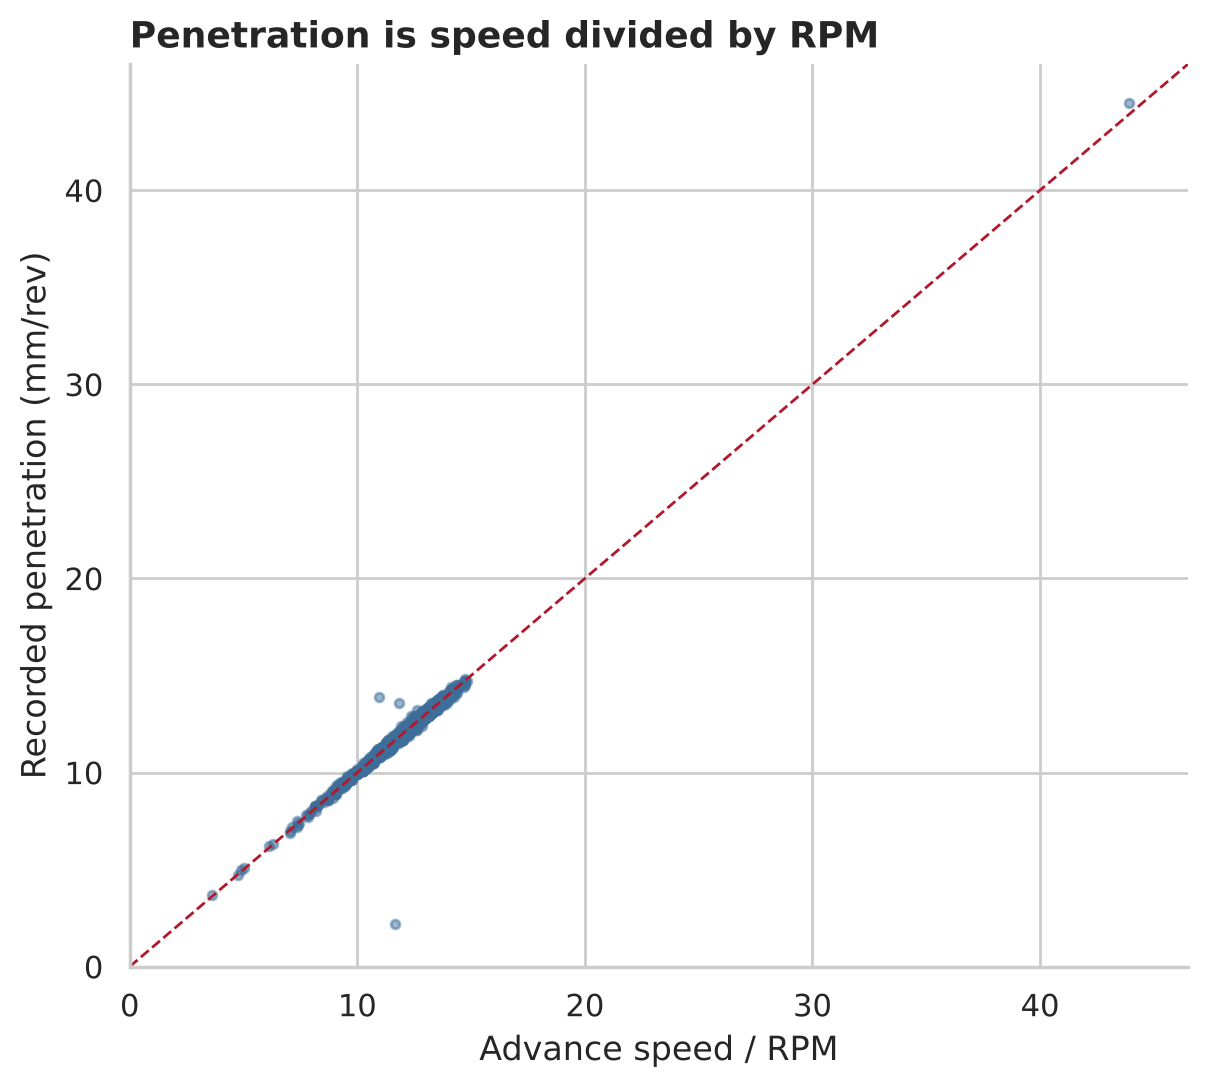

In [6]:
save(plot_penetration_check(raw), "penetration_equals_speed_over_rpm.png")

### Impossible readings

In [7]:
df, removed = clean(raw)
print(f"Strokes kept: {len(df)} of {len(raw)}")
removed

Strokes kept: 1456 of 1472


,section,sr,stroke_no,reason
0,1,1,3812,penetration above 25 mm/rev (three times the n...
1,1,5,3816,gripper pressure above 400 bar
2,3,145,4009,advance time of 0 minutes
3,4,8,4038,"excavation per stroke 0 or less, or above 2.5 m"
4,4,23,4053,gripper pressure above 400 bar
5,4,39,4069,"excavation per stroke 0 or less, or above 2.5 m"
6,4,48,4078,front shield pressure RHS below 5 or above 120...
7,4,86,3368,"excavation per stroke 0 or less, or above 2.5 m"
8,4,147,3429,"excavation per stroke 0 or less, or above 2.5 m"
9,5,187,3671,advance time of 0 minutes


A gripper pressure above 1,000 bar, a negative or 14 m excavation per stroke, a zero advance time and a penetration of 44.5 mm/rev (three times the typical value, from a stroke with an advance speed far above any other) are recording errors, so these 16 strokes are removed.

## 4. Exploring the log

In [8]:
df[TARGET].describe().round(2)

count    1456.00
mean       11.98
std         1.35
min         3.70
25%        11.30
50%        12.20
75%        12.90
max        14.80
Name: penetration_mm_rev, dtype: float64

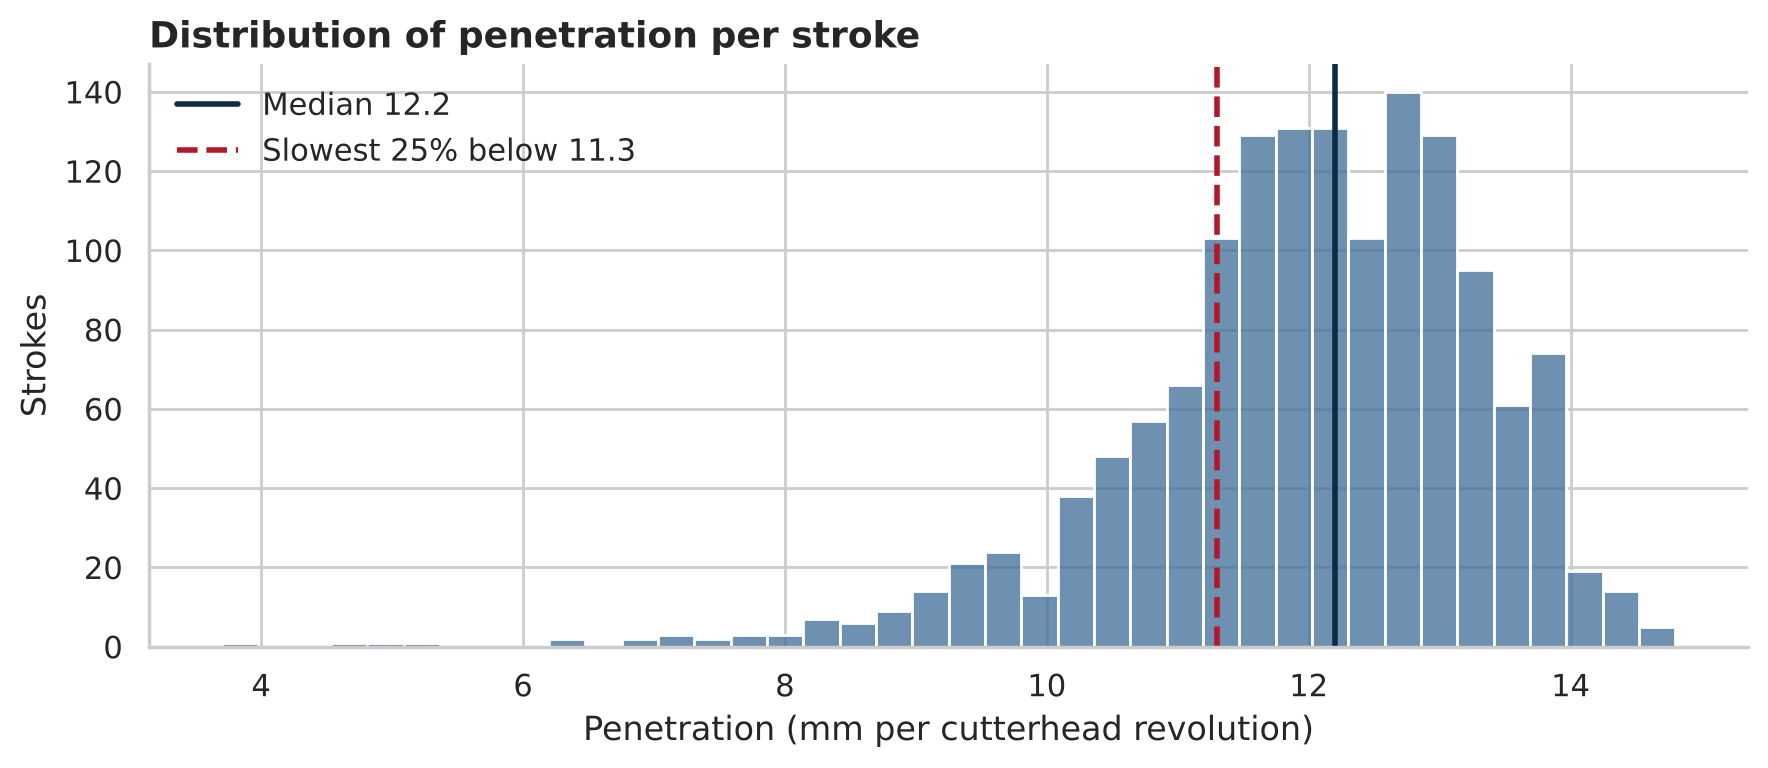

In [9]:
save(plot_penetration_distribution(df), "penetration_distribution.png")

In [10]:
correlations_with_target(df)

,column,label,correlation
0,boring_energy_n_mm2,Boring energy (N/mm2),-0.528
1,thrust_kn,Thrust force (kN),-0.502
2,total_revolutions,Total revolutions,-0.487
3,gripper_bar,Gripper pressure (bar),-0.316
4,advance_time_min,Advance time (min),-0.261
5,torque_knm,Torque (kN-m),-0.259
6,rpm,Cutterhead RPM,-0.252
7,q_value_njc,Rock mass Q-value (NJC),-0.144
8,shield_rhs_bar,Front shield pressure RHS (bar),0.110
9,shield_lhs_bar,Front shield pressure LHS (bar),0.141


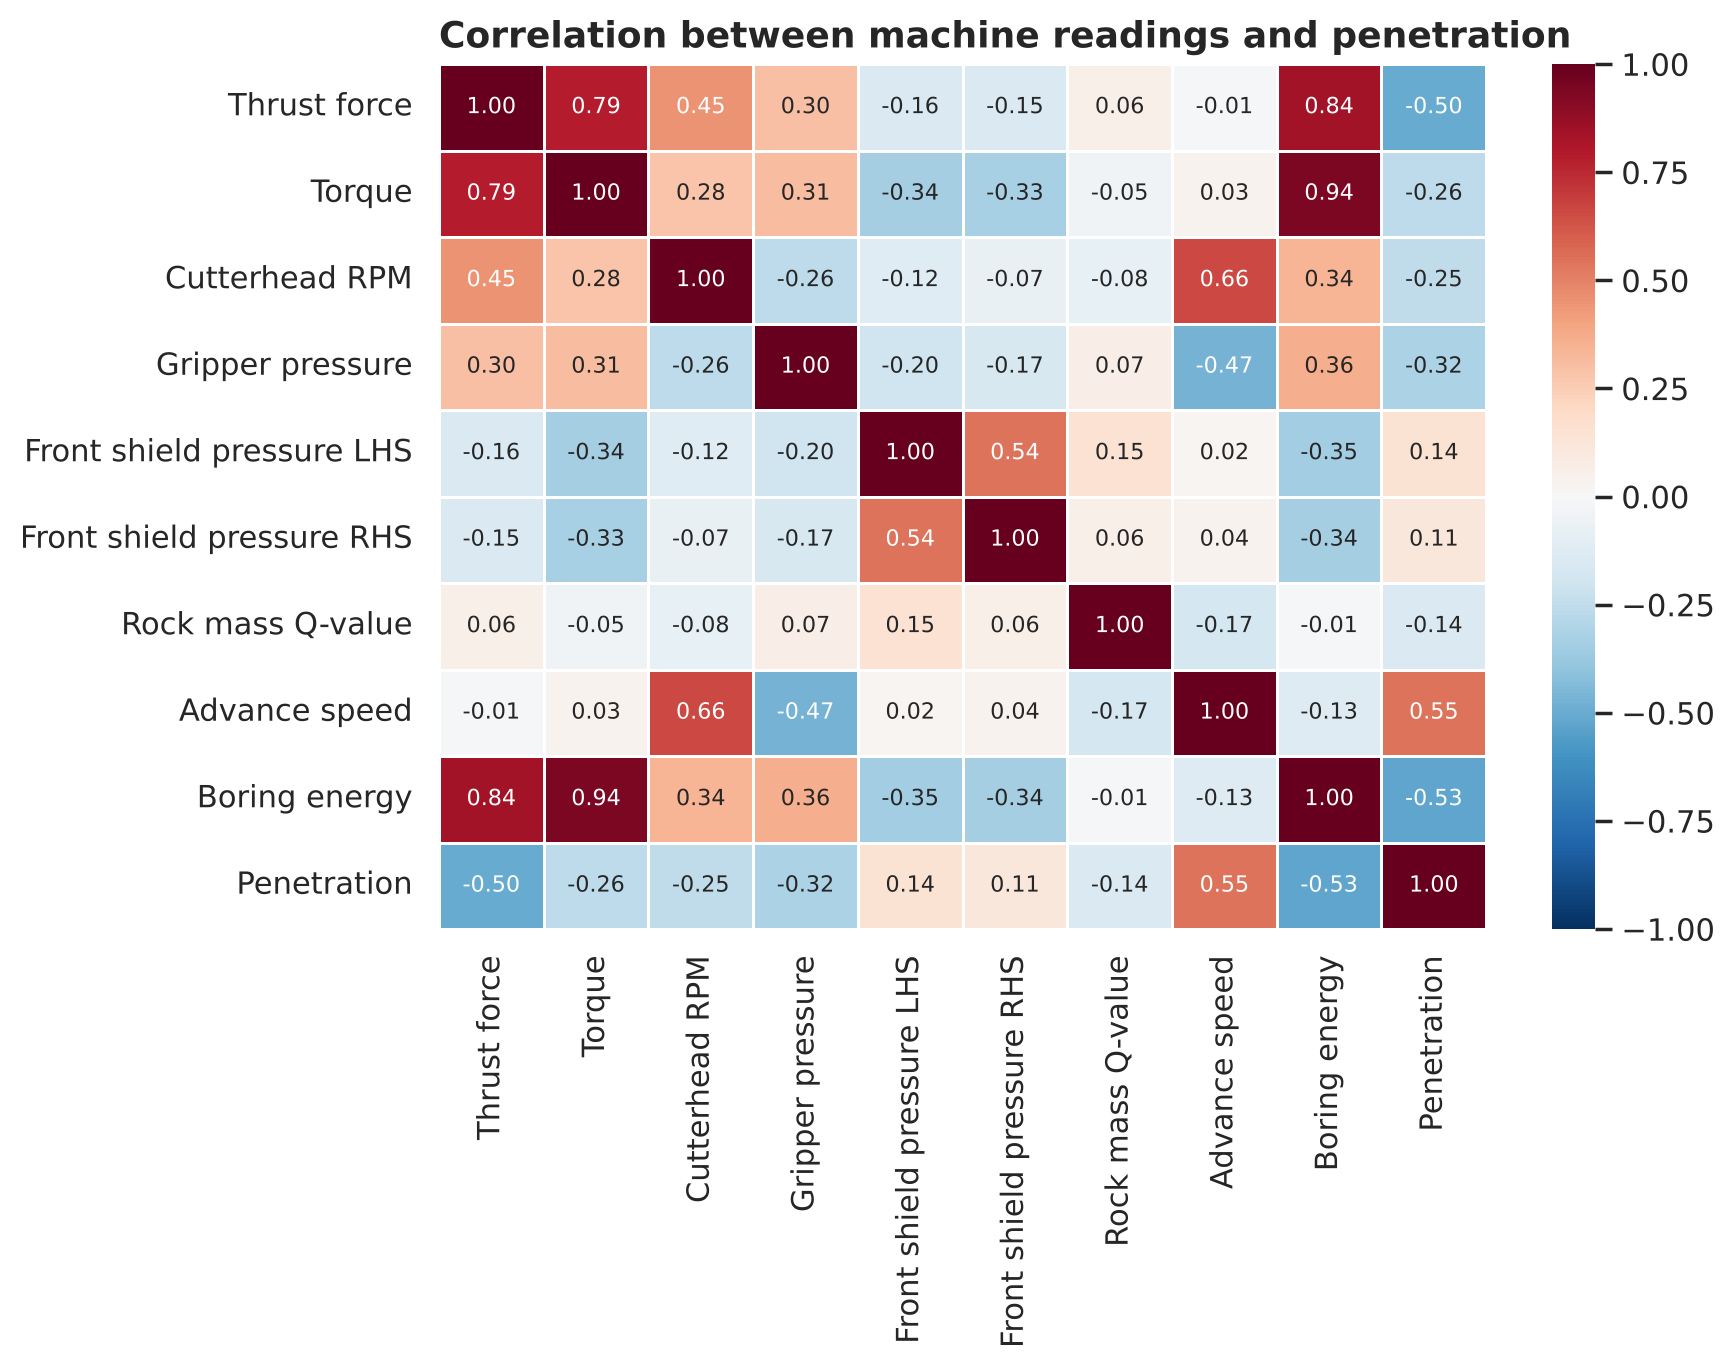

In [11]:
save(plot_correlation_heatmap(df), "correlation_heatmap.png")

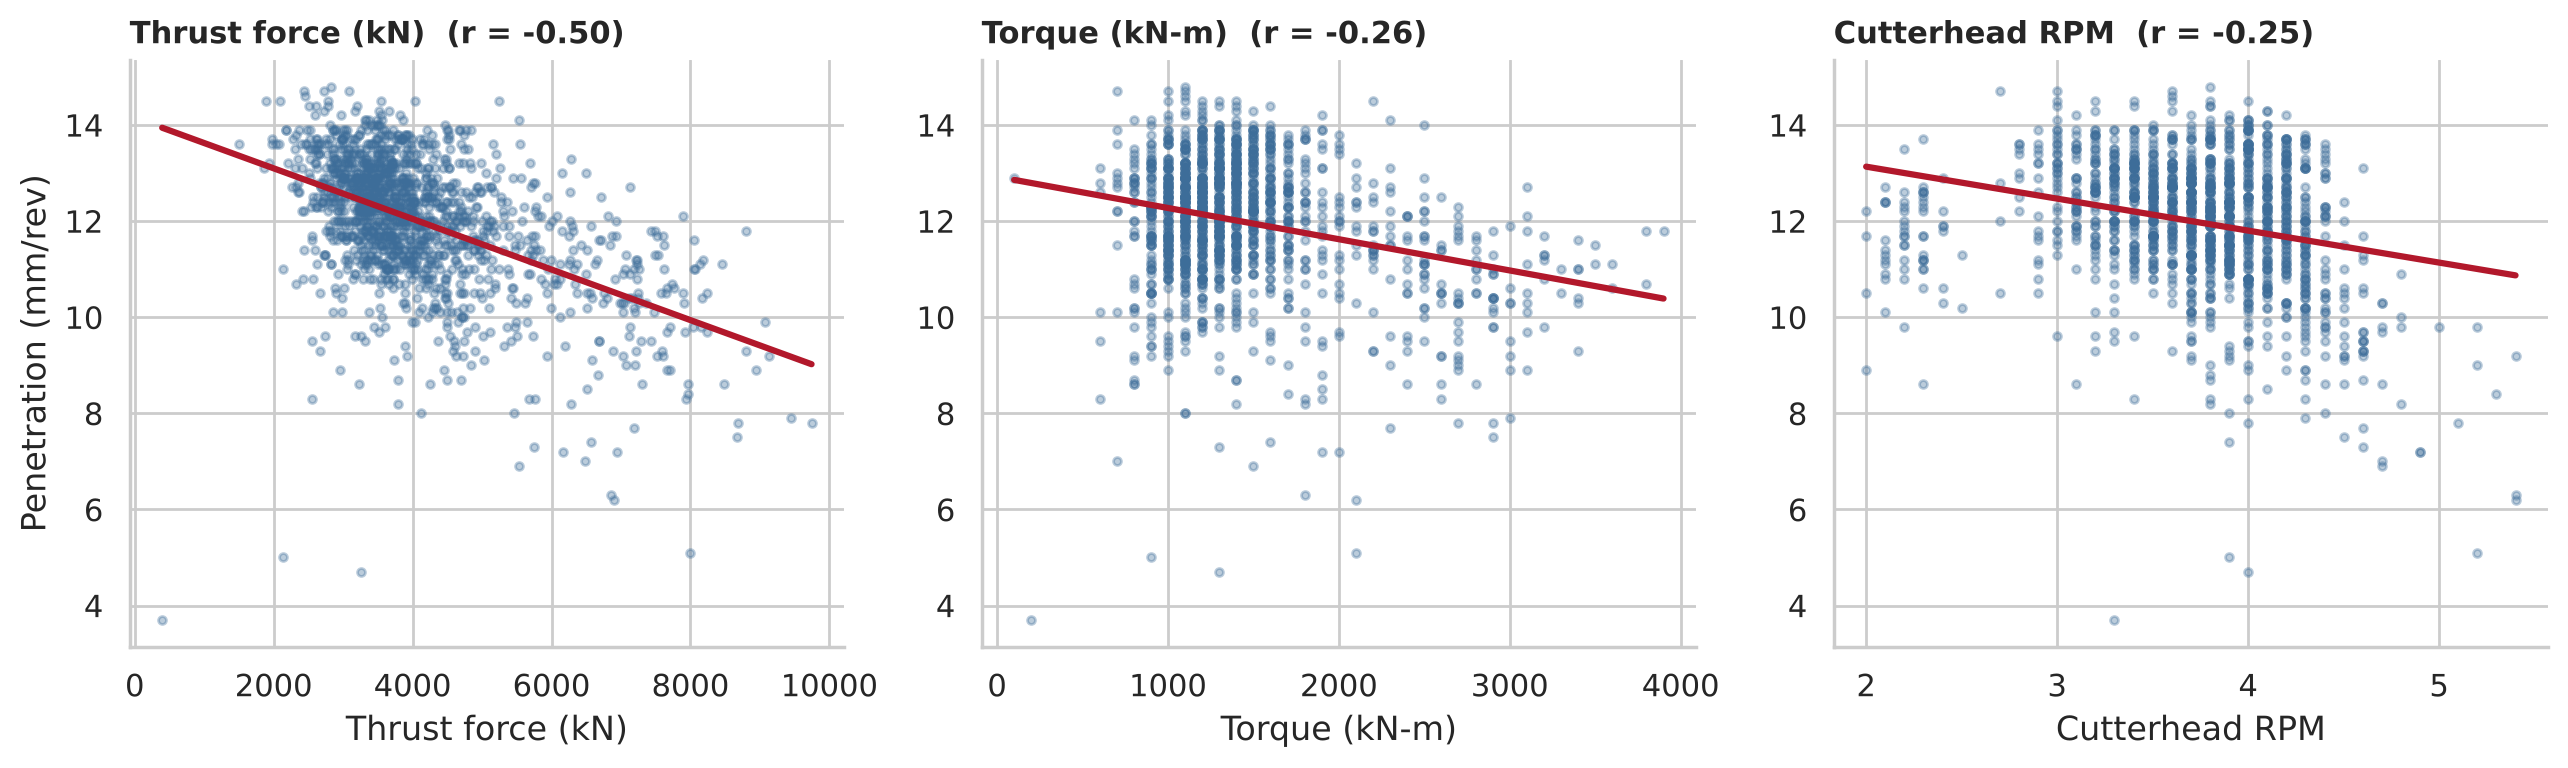

In [12]:
save(plot_drivers(df), "thrust_torque_rpm_vs_penetration.png")

Penetration falls as thrust rises (r = -0.50). That looks backwards, since pushing harder should cut deeper. The likely reason is that operators raise thrust in harder rock, where penetration is lower anyway, so thrust partly measures how hard the ground is.

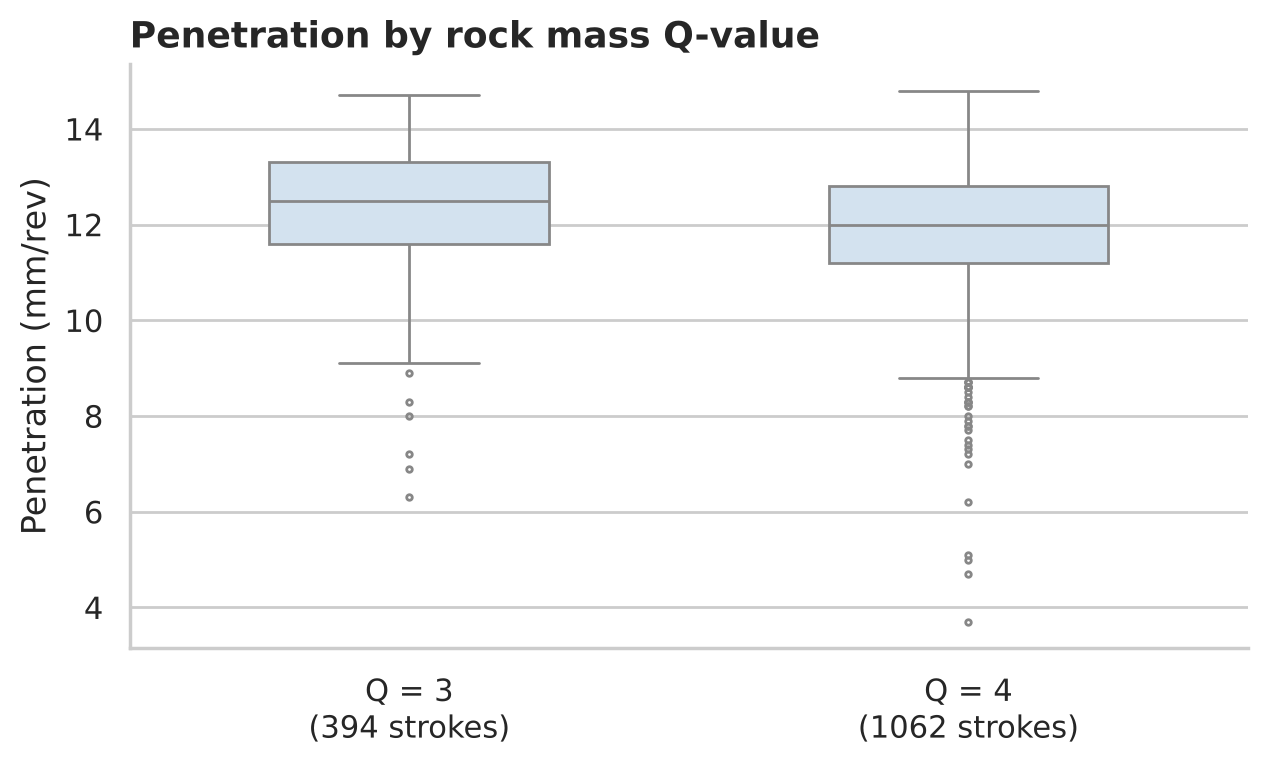

In [13]:
save(plot_rock_quality(df), "penetration_by_q_value.png")

In [14]:
df.groupby("q_value_njc")[TARGET].agg(["count", "mean", "median"]).round(2)

,count,mean,median
q_value_njc,,,
3,394,12.30,12.5
4,1062,11.87,12.0


Strokes in rock with a Q-value of 4 (better quality, more intact rock) penetrate slightly less than those at Q = 3, which fits harder, more competent rock being slower to cut.

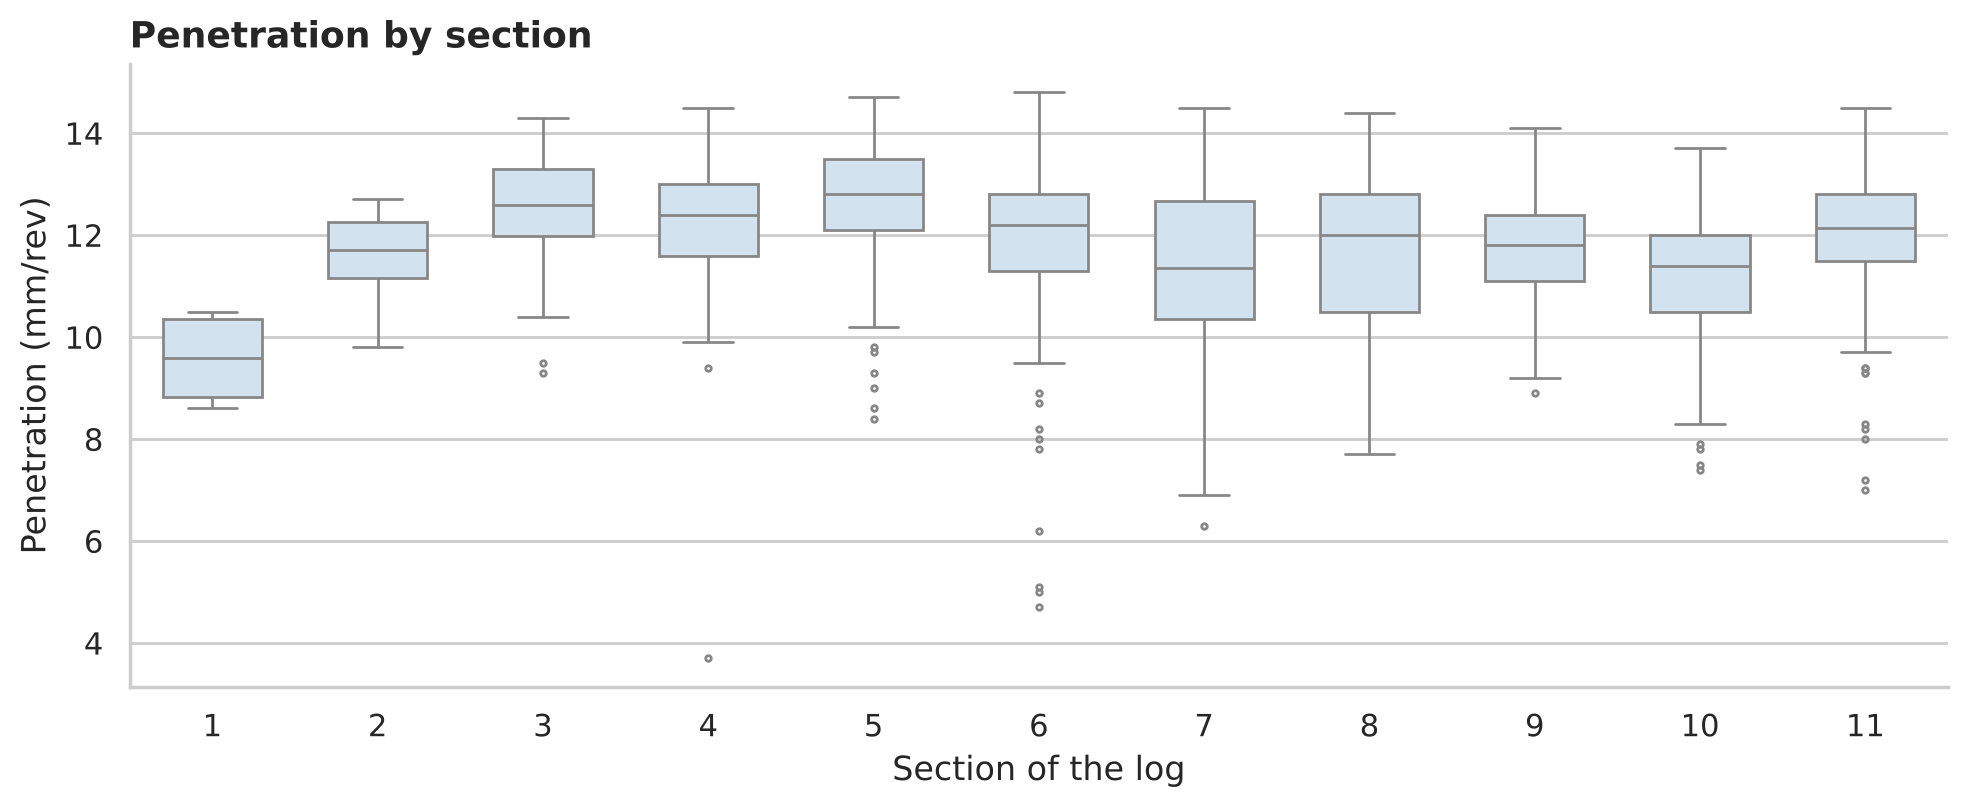

In [15]:
save(plot_by_section(df), "penetration_by_section.png")

In [16]:
section_summary(df)

,section,strokes,first_stroke,last_stroke,mean_penetration,mean_thrust_kn,share_q4_%
0,1,4,3813,3817,9.57,3237.0,100.0
1,2,43,3819,3861,11.60,3296.0,100.0
2,3,164,3865,4030,12.56,3513.0,85.0
3,4,195,3362,4109,12.29,4036.0,96.0
4,5,211,3485,3696,12.66,4378.0,57.0
5,6,205,3697,3902,11.90,3477.0,83.0
6,7,126,3903,4028,11.37,3802.0,56.0
7,8,126,4089,4214,11.68,4430.0,46.0
8,9,125,4317,4442,11.76,4908.0,62.0
9,10,127,4545,4673,11.20,5457.0,65.0


## 5. Modeling approach

**Inputs** (known before the next stroke is bored):

- Machine readings: thrust, torque, RPM, gripper pressure, front shield pressures
- Rock mass Q-value
- History: penetration of the previous stroke, and the average of the last five strokes in the same section

**Not used:**

- Advance speed, because penetration = speed / RPM
- Boring energy and the Q class based on it, because boring energy = torque x RPM / speed
- Advance time, excavation length and total revolutions, which are only known once the stroke ends
- Stroke number and date (see section 3)

**Validation:** consecutive strokes are very similar. With a random split, the test set would contain strokes whose neighbours were in training, and the model could score well by copying them. Instead, each of the 11 sections is predicted by a model trained only on other sections (GroupKFold with 5 folds).

In [17]:
data = modeling_rows(df)
print("Strokes with a previous stroke in the same section:", len(data))
print("Inputs:", FEATURES)

Strokes with a previous stroke in the same section: 1445
Inputs: ['thrust_kn', 'torque_knm', 'rpm', 'gripper_bar', 'shield_lhs_bar', 'shield_rhs_bar', 'q_value_njc', 'prev_penetration', 'mean_penetration_last_5']


## 6. Leakage check

In [18]:
leakage_demo(df)

,inputs,R2,MAE_mm_rev
0,"Machine readings, rock quality and history",0.471,0.72
1,... plus Advance speed (penetration = speed / ...,0.890,0.26
2,... plus Boring energy (= torque x RPM / speed),0.680,0.52


Adding advance speed jumps R2 to 0.89 because it gives the model the answer. Boring energy has the same problem in a weaker form. Neither is available before a stroke is bored.

## 7. Model comparison

In [19]:
comparison = compare_models(df)
comparison.to_csv(RESULTS / "model_comparison.csv", index=False)
comparison

,inputs,model,R2,MAE_mm_rev
0,none,Always predict the average,-0.022,1.04
1,previous stroke,Repeat the previous stroke,0.246,0.84
2,machine readings and rock quality,Ridge Regression,0.264,0.88
3,machine readings and rock quality,Random Forest,0.298,0.87
4,machine readings and rock quality,Gradient Boosting,0.321,0.86
5,"machine readings, rock quality and history",Ridge Regression,0.444,0.75
6,"machine readings, rock quality and history",Random Forest,0.471,0.72
7,"machine readings, rock quality and history",Gradient Boosting,0.466,0.73


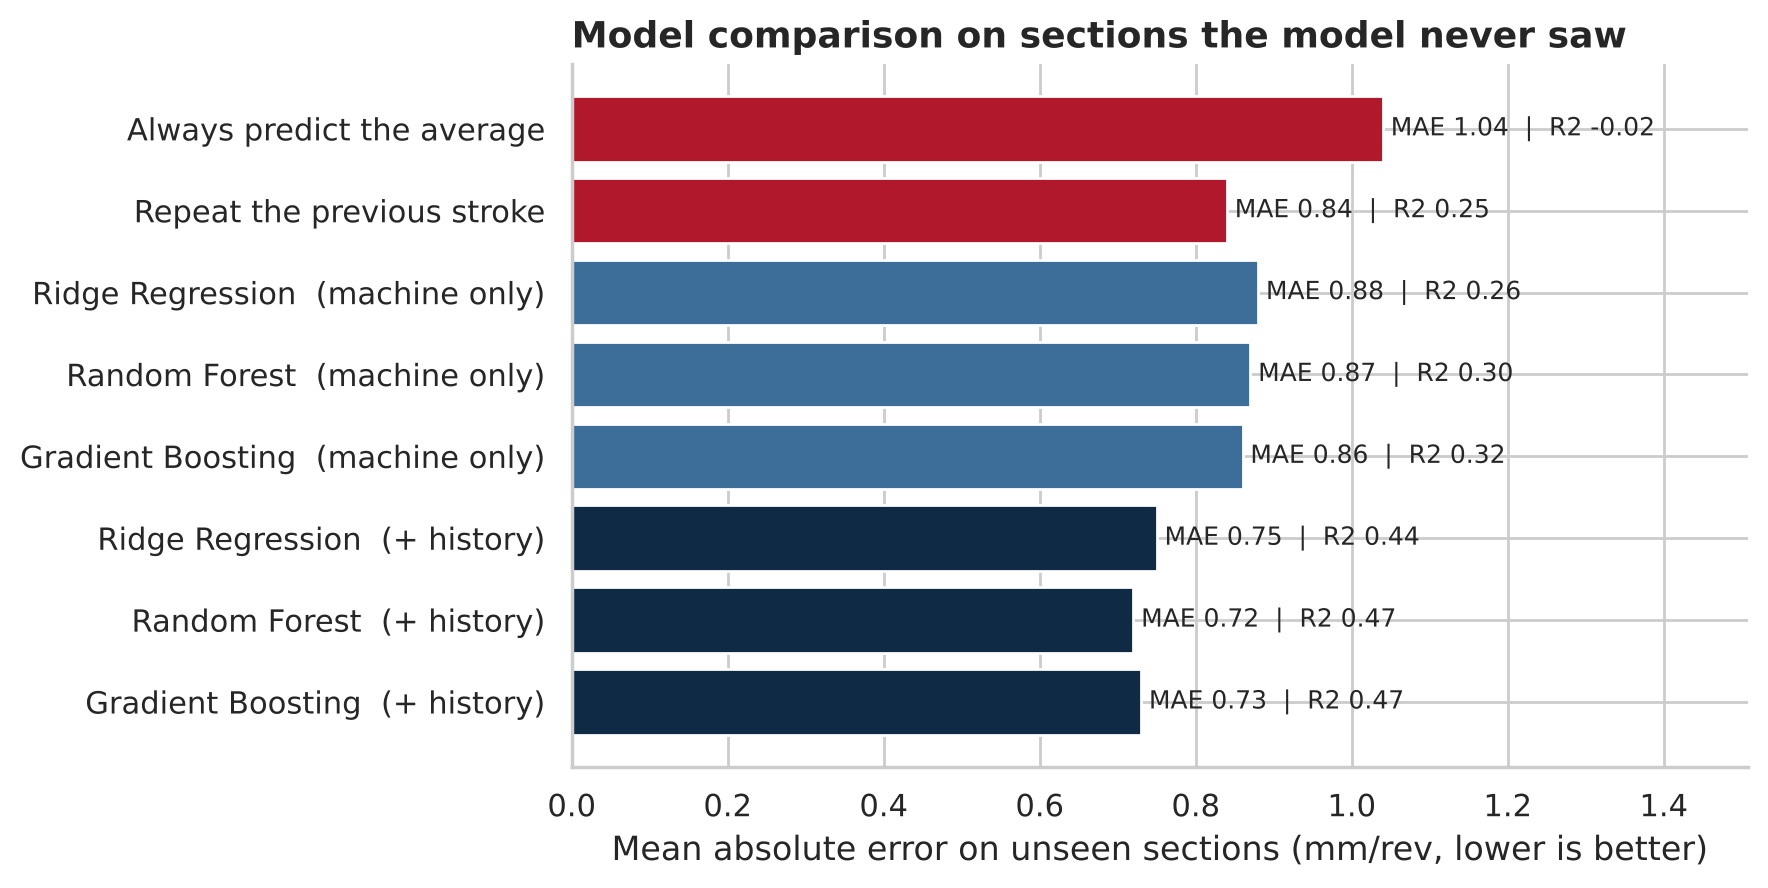

In [20]:
save(plot_model_comparison(comparison), "model_comparison.png")

In [21]:
validation_check(df)

,validation,R2,MAE_mm_rev
0,Random 5-fold split,0.512,0.69
1,Leave whole sections out (GroupKFold),0.471,0.72


A random split scores higher than leaving sections out (R2 0.51 against 0.47). The section split is the honest number, because a new stretch of tunnel is always new ground.

In [22]:
preds = out_of_section_predictions(df)
preds.to_csv(RESULTS / "out_of_section_predictions.csv", index=False)
print("Strokes predicted within 1 mm/rev:", round((preds["error"].abs() <= 1).mean() * 100, 1), "%")

Strokes predicted within 1 mm/rev: 74.6 %


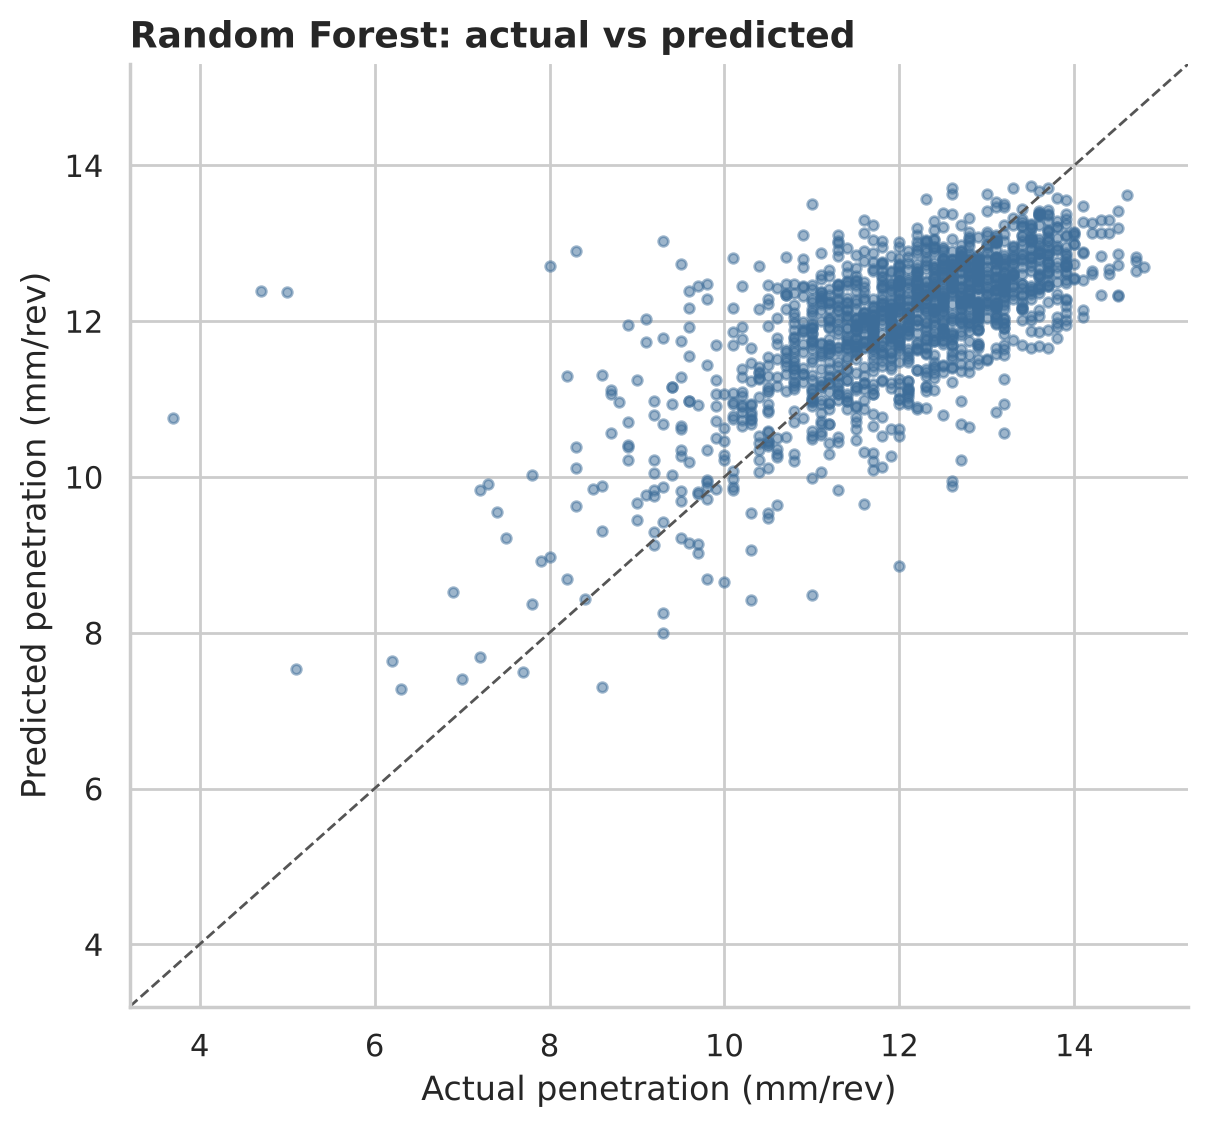

In [23]:
save(plot_actual_vs_predicted(preds), "actual_vs_predicted.png")

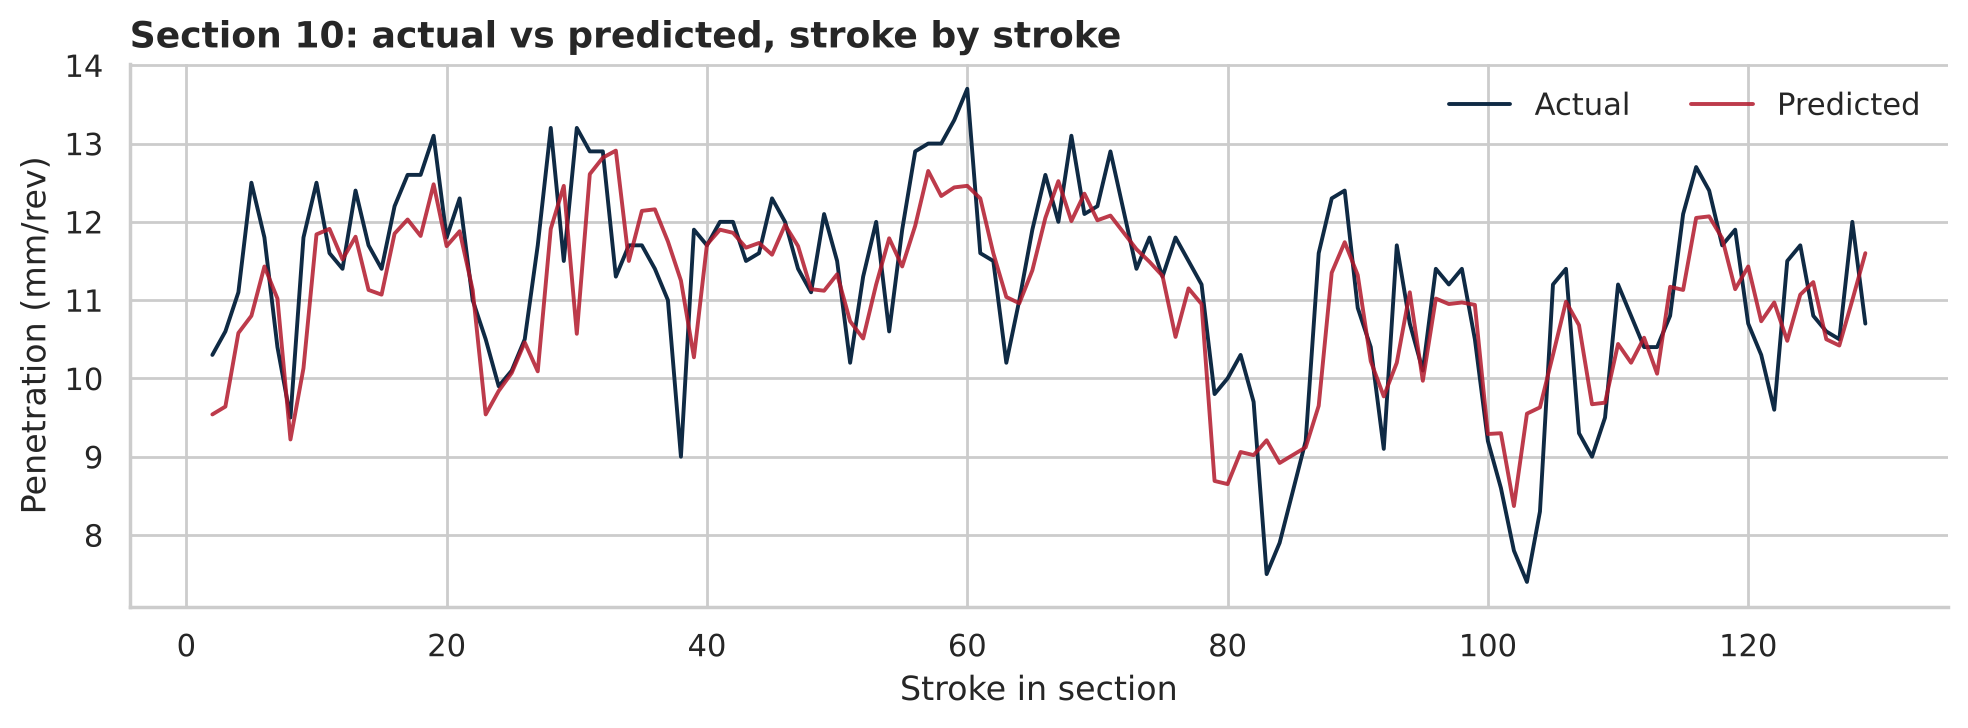

In [24]:
save(plot_section_trace(df, preds, 10), "section_10_trace.png")

## 8. What the model relies on

In [25]:
importance = feature_importance(df)
importance.to_csv(RESULTS / "feature_importance.csv", index=False)
importance[["label", "MAE_increase"]]

,label,MAE_increase
0,Prev penetration,0.207
1,Thrust force (kN),0.110
2,Cutterhead RPM,0.038
3,Torque (kN-m),0.030
4,Mean penetration last 5,0.023
5,Gripper pressure (bar),0.008
6,Rock mass Q-value (NJC),0.001
7,Front shield pressure LHS (bar),0.000
8,Front shield pressure RHS (bar),-0.002


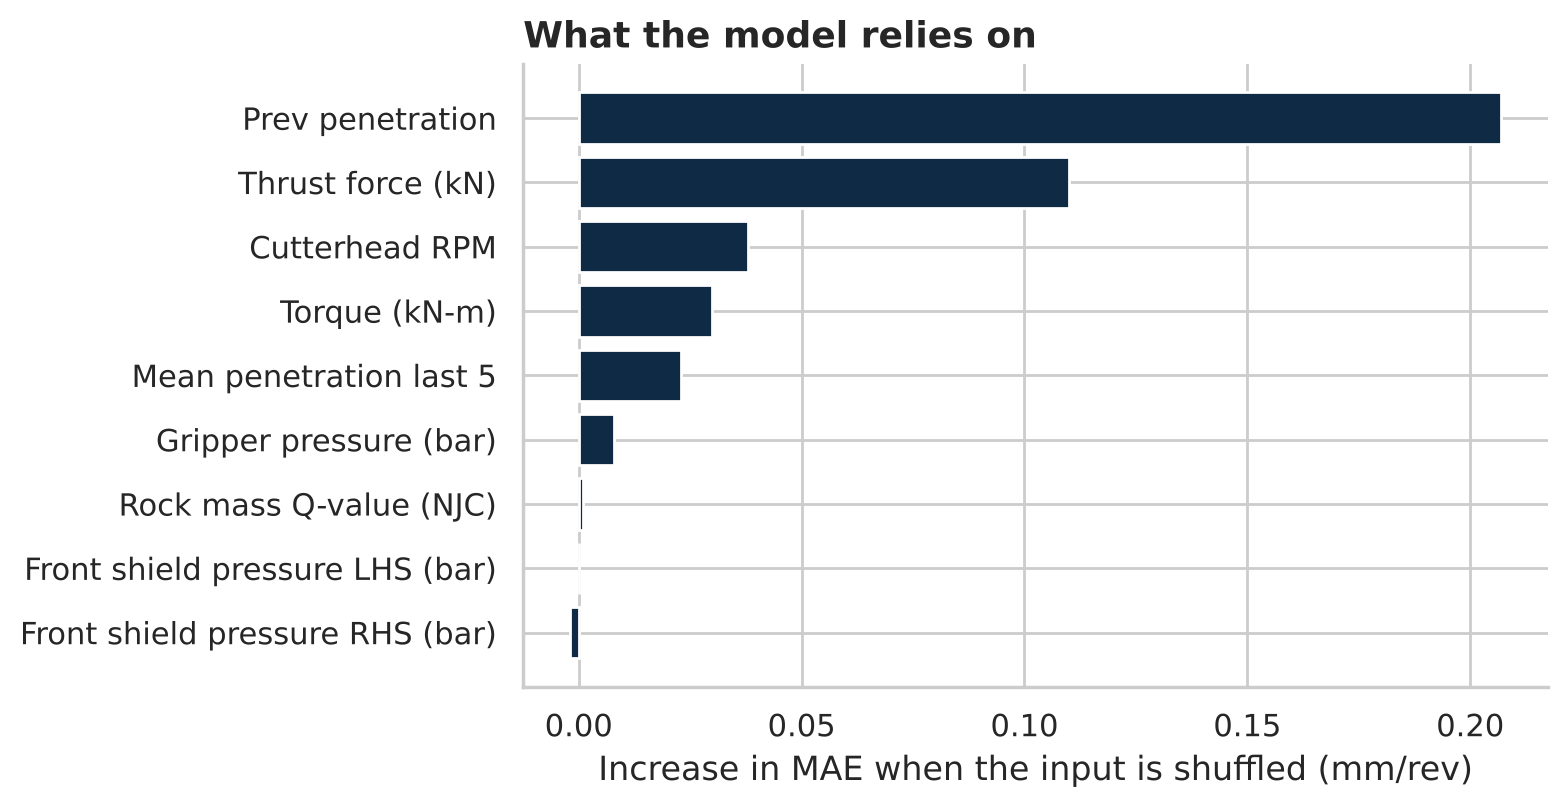

In [26]:
save(plot_feature_importance(importance), "feature_importance.png")

## 9. Flagging slow strokes

The first version of this project tried to sort strokes into classes with a fixed rule on boring pressure. Every stroke landed in the same class, so the model reported 100% accuracy without learning anything.

Here the class comes from the real penetration: a stroke is **slow** if it is in the slowest quarter of the log.

In [27]:
classification, cm, threshold = classify_low_penetration(df)
print(f"Slow stroke: penetration below {threshold:.1f} mm/rev")
classification

Slow stroke: penetration below 11.3 mm/rev


,model,ROC_AUC,balanced_accuracy,slow_strokes_caught_%,false_alarms_%
0,Logistic Regression,0.815,0.758,73.938,22.344
1,Random Forest,0.833,0.756,66.856,15.659


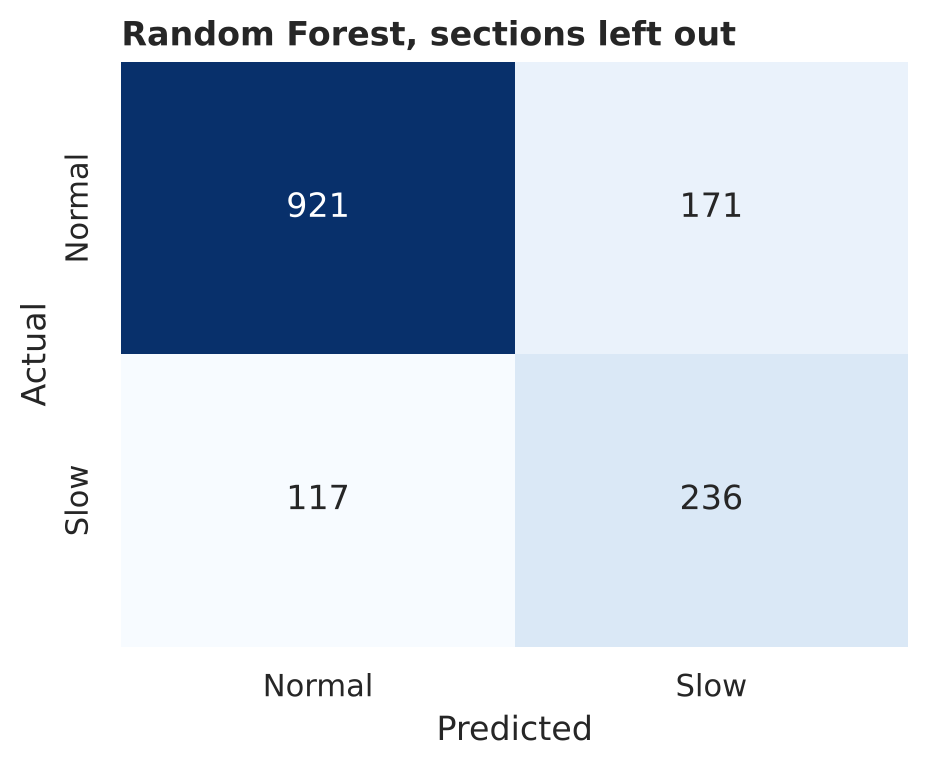

In [28]:
fig, ax = plt.subplots(figsize=(4.8, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Normal", "Slow"], yticklabels=["Normal", "Slow"])
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Random Forest, sections left out", loc="left", fontweight="bold")
fig.tight_layout()
save(fig, "slow_stroke_confusion_matrix.png")

## 10. Findings

1. **The log needed real cleaning.** It has a three-row header, 11 sections with a restarting serial number, swapped day and month in some dates, and 16 impossible readings.
2. **Penetration is defined as speed / RPM**, and boring energy is built from speed. Using either as an input is leakage: it lifts R2 from 0.47 to 0.89.
3. **Next-stroke penetration can be predicted to within 0.72 mm/rev on average** (R2 0.47) for sections the model never saw, against 1.04 mm/rev for always predicting the average and 0.84 for repeating the previous stroke. 75% of strokes are within 1 mm/rev.
4. **Recent history matters most**, then thrust, RPM and torque. Rock Q-value and shield pressures add little.
5. **Slow strokes can be flagged ahead of time** with ROC AUC 0.83: the model catches two thirds of them with a 16% false alarm rate.
6. **Higher thrust goes with lower penetration**, most likely because operators push harder in harder ground.

**Limitations:** one drive, one year and a Q-value with only two levels. More detailed geology (rock strength, joint spacing, abrasivity) would be needed for larger gains.